# plot input layer 

## Nasa Tb
- NASA Global Merged IR V1 brightness temperature product (NASA-Tb)
- Janowiak et al. 2001
- INFO GPM: https://gpm.nasa.gov/data/directory/ncepcpc-level-3-merged-infrared-brightness-temperatures-0
- GES DISC doc: https://disc.gsfc.nasa.gov/datasets/GPM_MERGIR_1/summary
- https://www.earthdata.nasa.gov/data/catalog/ges-disc-gpm-mergir-1

## IMERG
- GPM IMERG Final Precipitation L3 Half Hourly 0.1 degree x 0.1 degree V07
- Huffman, G.J., E.F. Stocker, D.T. Bolvin, E.J. Nelkin, Jackson Tan (2023), GPM IMERG Final Precipitation L3 Half Hourly 0.1 degree x 0.1 degree V07, Greenbelt, MD, Goddard Earth Sciences Data and Information Services Center (GES DISC), Accessed: [Data Access Date], 10.5067/GPM/IMERG/3B-HH/07   
- https://disc.gsfc.nasa.gov/datasets/GPM_3IMERGHH_07/summary?keywords=%22IMERG%20final%22

 ## CCIC
**CCIC IWP**
- Chalmers Cloud Ice Climatology CPCIR
- Amell, A., Pfreundschuh, S., and Eriksson, P.: The Chalmers Cloud Ice Climatology: Retrieval implementation and validation, EGUsphere [preprint], https://doi.org/10.5194/egusphere-2023-1953  
- AWS: https://registry.opendata.aws/ccic/
- documentation: https://ccic.readthedocs.io/en/latest/dataset_and_file_structure.html
- following code adapted from documentation website


## infos
- **Prerequisite**: Credential files for earthdata (https://github.com/nasa/gesdisc-tutorials/blob/main/notebooks/How_to_Generate_Earthdata_Prerequisite_Files.ipynb)
        - edl token needs to be refreshed every 60 days! (Step 3.)
    - How to generate Prerequisted ErathData files https://github.com/nasa/gesdisc-tutorials/blob/main/notebooks/How_to_Generate_Earthdata_Prerequisite_Files.ipynb
        - **files need to exist for this nbook to work!**
- based on: 
    - example nbook for download and open IMERG (Monthly) https://github.com/nasa/gesdisc-tutorials/blob/main/notebooks/How_to_Read_IMERG_Data_Using_Python.ipynb)
    - How_to_Access_GES_DISC_Data_Using_Python: https://github.com/nasa/gesdisc-tutorials/blob/main/notebooks/How_to_Access_GES_DISC_Data_Using_Python.ipynb
    - => adapted the last one for IMERG on 30min


In [1]:
import numpy as np
import xarray as xr


import warnings
warnings.filterwarnings("ignore", category=FutureWarning)


# 
import sys
sys.path.append("../tools/")
import handle_ICON_data as ic
import plots_mapping as pm

# load tools
import sys 
sys.path.append("../tools")
import handle_OBS_data


import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import seaborn as sns

import os


In [2]:
date = "2023-06-06-1800"


output_directory = "../output/plots"
if not os.path.exists(os.path.join(output_directory)):
    os.makedirs(os.path.join(output_directory,), exist_ok=True)

In [3]:
# mean
tb = handle_OBS_data.load_calc_clean_mean_tb(date, buffer = 32, min_images= 5)
precip = handle_OBS_data.load_calc_clean_mean_imerg(date, buffer = 30, min_images= 5)
iwp = handle_OBS_data.load_calc_clean_mean_ccic(date, buffer = 32, min_images= 5)

# regrid 
# resample (data, precip)
tb_res = handle_OBS_data.resample_grids(tb,precip)  
iwp_res = handle_OBS_data.resample_grids(iwp,precip)  


QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

Tb data loaded for 2023-06-06-1800, if applicable both images returned, cropped, 'Tb' selected, longitude/latitude rename, assigned attrs,drop timedim


QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

...

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

/work/bb1376/user/leonie/master_thesis/nbooks_plotting/../tools/handle_OBS_data.py:207: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  imerg_clean["time"] = imerg_clean.indexes["time"].to_datetimeindex(time_unit = "ns")


IMERG data loaded for 2023-06-06-1530, cleaned, cropped, 'precipitation' selected, longitude/latitude rename, assigned attrs,drop timedim
CCIC data loaded for 2023-06-06-1800, if applicable both images returned, cleaned, cropped, 'tiwp' selected, longitude/latitude rename, assigned attrs, drop timedim
CCIC data loaded for 2023-06-06-1700, if applicable both images returned, cleaned, cropped, 'tiwp' selected, longitude/latitude rename, assigned attrs, drop timedim
CCIC data loaded for 2023-06-06-1600, if applicable both images returned, cleaned, cropped, 'tiwp' selected, longitude/latitude rename, assigned attrs, drop timedim
CCIC data loaded for 2023-06-06-1500, if applicable both images returned, cleaned, cropped, 'tiwp' selected, longitude/latitude rename, assigned attrs, drop timedim


In [4]:
# data selection
zoom = 9

vlist = ["pr", "rlut", "tas", "qsvi","clivi","qgvi","crs"]

# load data
dataset = ic.open_ngc4008(zoom = zoom) 

# select timestamp and variables
dataset = ic.select_time(dataset, date)
dataset = ic.select_vars(dataset, vlist)

# calculate input variables 
dataset = ic.add_input_vars(dataset)
dataset


# resample to Imerg grid
ds = {}
ds["tas"]= ic.resample_to_lon_lat(dataset,  "tas", zoom = zoom,to_imerg = True)
ds["tb"] = ic.resample_to_lon_lat(dataset, "tb_11", zoom = zoom, to_imerg = True)
ds["precip"] = ic.resample_to_lon_lat(dataset ,"rain_tot_rate", zoom = zoom ,to_imerg = True)
ds["iwp"] = ic.resample_to_lon_lat(dataset, "iwp", zoom = zoom,to_imerg = True)


In [5]:
# modify short names so that plotting has same labels in OBS and ICON

precip.attrs["short_name"] = "Rain rate"
precip.attrs["units"] = r"mm h$^{-1}$"

tb_res.attrs["short_name"] = "BT"

iwp_res.attrs["units"] = r"kg m$^{-2}$"


In [6]:
ds["precip"].attrs["short_name"]=  "Rain rate"
ds["precip"].attrs["units"] = r"mm h$^{-1}$"

ds["tb"].attrs["short_name"]  = "BT"

ds["iwp"].attrs["units"] = r"kg m$^{-2}$"

In [7]:
def summarized_domain_plot(tb, precip, iwp, title, domain=[-180,180,-30,30],
                           tb_vmin=200, tb_vmed=240, tb_vmax=300,
                           precip_vmin=0, precip_vmax=3,
                           iwp_vmin=1e-3, iwp_vmax=1e1):

    sns.set_context("talk")

    fig, axes = plt.subplots(
        3, 1,
        figsize=(12, 7),
        subplot_kw={"projection": ccrs.PlateCarree()},
        constrained_layout=True
    )

    pm.domain_plot_tb(tb, domain=domain, left_grid_label=True, bottom_grid_label=False,
                   title="a) BT",
                   vmin=tb_vmin, vmed=tb_vmed, vmax=tb_vmax,
                   fig=fig, ax=axes[0],shrink = 0.7)

    pm.domain_plot_precip(precip, vmin=precip_vmin, vmax=precip_vmax,
                       domain=domain, left_grid_label=True, bottom_grid_label=False,
                       title="b) Precip",
                       fig=fig, ax=axes[1],shrink = 0.7)

    pm.domain_plot_iwp(iwp, vmin=iwp_vmin, vmax=iwp_vmax,
                    domain=domain, left_grid_label=True, bottom_grid_label=True,
                    title="c) IWP",
                    fig=fig, ax=axes[2], shrink = 0.7)

    fig.suptitle(title, fontweight="bold")

    return fig

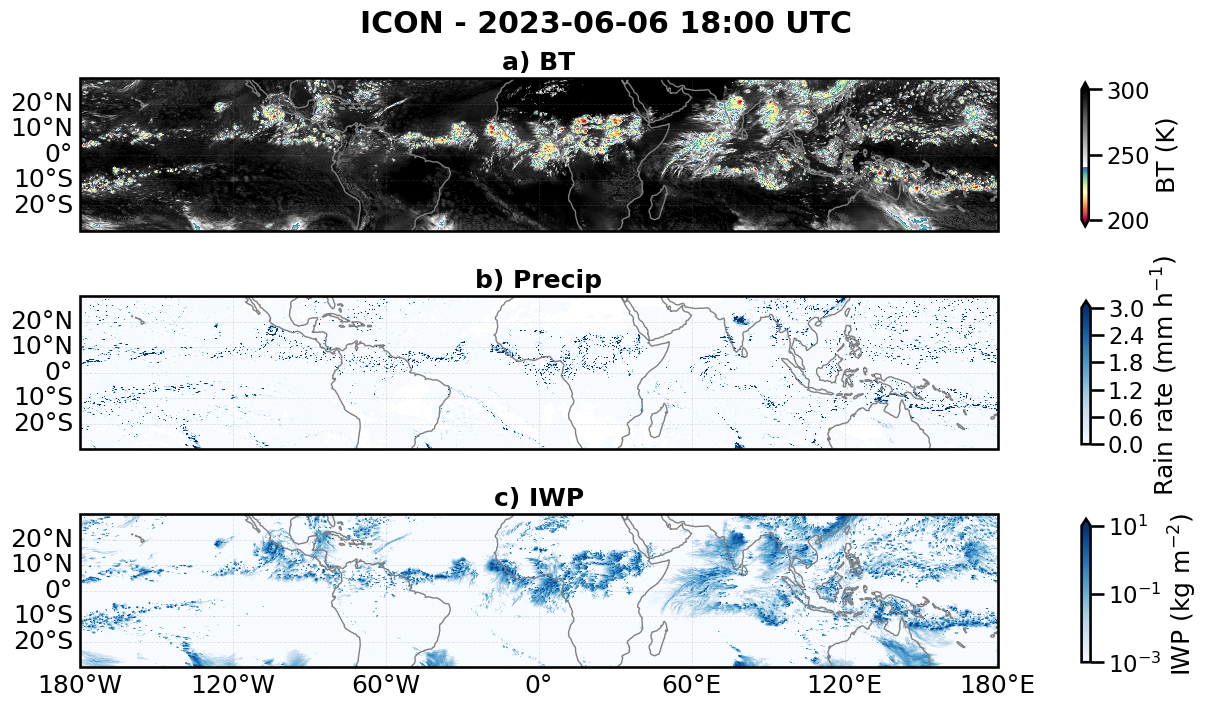

In [8]:
date_label = pm.title_time_format(iwp_res)
fig = summarized_domain_plot(tb = ds["tb"],precip = ds["precip"],iwp = ds["iwp"], title = f"ICON - {date_label} UTC") #Input Layer from 

In [9]:

    
fig.savefig(os.path.join(output_directory,f"input_layer_ICON_{date}.pdf"))

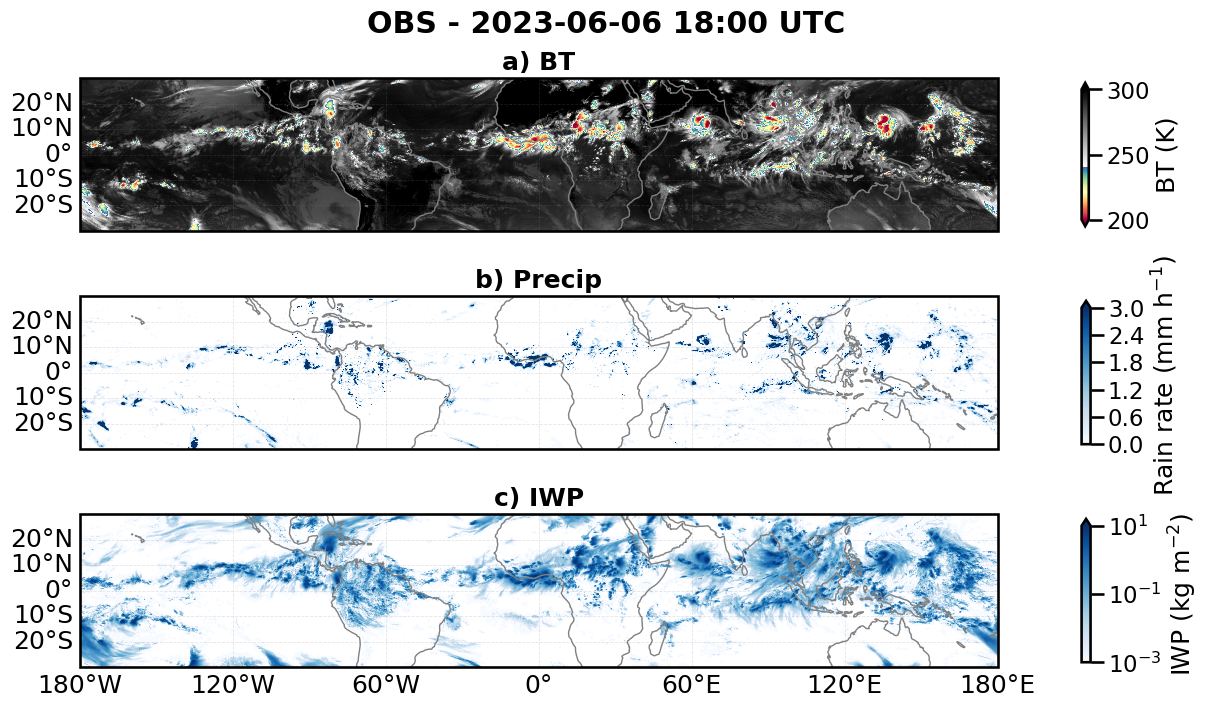

In [10]:
fig = summarized_domain_plot(tb =tb_res,precip = precip,iwp = iwp_res, title = f"OBS - {date_label} UTC") #Input Layer from

In [11]:

fig.savefig(os.path.join(output_directory,f"input_layer_OBS_{date}.pdf"))